In [1]:
import os
import glob
import numpy as np
import pandas as pd
from scipy.stats import zscore

#visualization libs
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

#statistics libs
from scipy.stats import ttest_ind, mannwhitneyu, kruskal
from scipy.stats import pearsonr, spearmanr

In [2]:
# Display settings
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:.2f}'.format) 

# Plot styling to keep all plots consistent
plt.rcParams.update({
    'figure.figsize':  (10, 6),
    'axes.titlesize':  14,
    'axes.labelsize':  12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.dpi':      100
})

# Color palette for health groups 
HEALTH_COLORS = {
    'Healthy': '#4CAF50',   # green'
    'PreD':    '#2196F3',   # blue
    'T2D':     '#F44336'    # red
}

# Path to data 
DATA_PATH = r"C:\Users\Laura\OneDrive\Desktop\BIOMED_PROJECT\CGMacros"


In [3]:
def classify_health(a1c):
    """Classify subject health status based on A1c value"""
    if a1c < 5.7:
        return 'Healthy'
    elif a1c <= 6.4:
        return 'PreD' #prediabetic
    else:
        return 'T2D' #type2 diabetes

In [4]:
bio_path = os.path.join(DATA_PATH, "bio.csv")
bio_df = pd.read_csv(bio_path)
print(f"bio.csv loaded: {bio_df.shape[0]} subjects, "
      f"{bio_df.shape[1]} columns")

# Clean column names first (several have trailing spaces)
bio_df.columns = bio_df.columns.str.strip()

# Check columns to observe features
print(bio_df.columns)

bio.csv loaded: 45 subjects, 24 columns
Index(['subject', 'Age', 'Gender', 'BMI', 'Body weight', 'Height',
       'Self-identify', 'A1c PDL (Lab)', 'Fasting GLU - PDL (Lab)', 'Insulin',
       'Triglycerides', 'Cholesterol', 'HDL', 'Non HDL', 'LDL (Cal)',
       'VLDL (Cal)', 'Cho/HDL Ratio', 'Collection time PDL (Lab)',
       '#1 Contour Fingerstick GLU', 'Time (t)', '#2 Contour Fingerstick GLU',
       'Time (t).1', '#3 Contour Fingerstick GLU', 'Time (t).2'],
      dtype='str')


In [5]:
# Check for column types and missing values
print("COLUMN TYPES & MISSING VALUES")
summary = pd.DataFrame({
    'dtype':   bio_df.dtypes,
    'missing': bio_df.isnull().sum(),
    'sample':  bio_df.iloc[0]
})
print(summary.to_string())

COLUMN TYPES & MISSING VALUES
                              dtype  missing           sample
subject                       int64        0                1
Age                           int64        0               27
Gender                          str        0                M
BMI                         float64        0            22.27
Body weight                 float64        0           133.80
Height                      float64        0            65.00
Self-identify                   str        0  Hispanic/Latino
A1c PDL (Lab)               float64        0             5.40
Fasting GLU - PDL (Lab)       int64        0               91
Insulin                     float64        0             2.50
Triglycerides                 int64        0               67
Cholesterol                   int64        0              216
HDL                           int64        0               74
Non HDL                       int64        0              142
LDL (Cal)                     int64     

In [6]:
# 1. Fix subject ID to match the ones from the meals (001, 002, etc.)
bio_df['subject'] = bio_df['subject'].astype(str).str.zfill(3)

# 2. Classify health groups from A1c
bio_df['Health_group'] = bio_df['A1c PDL (Lab)'].apply(classify_health)

print("Health group distribution:")
print(bio_df['Health_group'].value_counts().to_string())

Health group distribution:
Health_group
PreD       16
Healthy    15
T2D        14


In [7]:
# 3. Calculate HOMA-IR (insulin resistance index)

# Formula: HOMA-IR = (fasting insulin × fasting glucose) / 405
# Insulin in uIU/mL, glucose in mg/dL
bio_df['HOMA_IR'] = (bio_df['Insulin'] * bio_df['Fasting GLU - PDL (Lab)']) / 405

In [8]:
# 4. Decide which columns to keep 
KEEP_COLS = [
    'subject',
    'Health_group',       # derived - primary grouping variable
    'Age',
    'Gender',
    'BMI',
    'A1c PDL (Lab)',      # renamed below
    'Fasting GLU - PDL (Lab)',
    'Insulin',
    'HOMA_IR',            # derived
    'Triglycerides',
    'Cholesterol',
    'HDL',
    'Non HDL',
    'LDL (Cal)',
    'VLDL (Cal)',
    'Cho/HDL Ratio',
]

bio_clean = bio_df[KEEP_COLS].rename(columns={
    'A1c PDL (Lab)':           'A1c',
    'Fasting GLU - PDL (Lab)': 'Fasting_glucose',
    'LDL (Cal)':               'LDL',
    'VLDL (Cal)':              'VLDL',
    'Cho/HDL Ratio':           'Cho_HDL_ratio',
    'Non HDL':                 'Non_HDL',
})

print(f"\nbio_clean shape: {bio_clean.shape}")
print(bio_clean.head(3).to_string())


bio_clean shape: (45, 16)
  subject Health_group  Age Gender   BMI  A1c  Fasting_glucose  Insulin  HOMA_IR  Triglycerides  Cholesterol  HDL  Non_HDL  LDL  VLDL  Cho_HDL_ratio
0     001      Healthy   27      M 22.27 5.40               91     2.50     0.56             67          216   74      142  130    13           2.90
1     002      Healthy   49      F 30.95 5.50               93    14.80     3.40             61          181   91       90   78    12           2.00
2     003          T2D   59      F 26.95 6.50              118    17.40     5.07            154          190   74      116   90    31           2.60


In [9]:
from scipy.integrate import trapezoid

def calc_iauc(cgm, sampling_interval=15):
    """Calculate incremental AUC above baseline"""
    a = [i * sampling_interval for i in range(len(cgm))]
    total = 0
    for i in range(len(cgm) - 1):
        b0 = cgm[i]   - cgm[0]
        b1 = cgm[i+1] - cgm[0]
        if b1 >= 0 and b0 >= 0:
            total += ((b0 + b1) / 2) * sampling_interval
        elif b1 < 0 and b0 >= 0:
            total += (b0 * (b0 / (b0 - b1)) * sampling_interval / 2)
        elif b1 >= 0 and b0 < 0:
            total += (b1 * (b1 / (b1 - b0)) * sampling_interval / 2)
    return total

def calc_auc(cgm, sampling_interval=15):
    """Calculate total AUC using trapezoid rule"""
    return trapezoid(cgm, dx=sampling_interval)

In [10]:
def get_col(data, col, default=np.nan):
    """Return column if it exists, else a NaN series."""
    if col in data.columns:
        return data[col]
    return pd.Series([default] * len(data), index=data.index)

# Canonical meal type mapping - covers case variants and label variants discovered in the previous audit 
MEAL_TYPE_MAP = {
    'breakfast': 'Breakfast',
    'lunch':     'Lunch',
    'dinner':    'Dinner',
    'snack':     'Snack',
    'snacks':    'Snack',   # plural variant
    'snack 1':   'Snack',   # numbered variant (CGMacros-009)
}


In [11]:
VALID_MEAL_TYPES = {'Breakfast', 'Lunch', 'Dinner'}
all_meals = []

for sub_folder in sorted(os.listdir(DATA_PATH)):
    if not sub_folder.startswith("CGMacros"):
        continue

    csv_path = os.path.join(DATA_PATH, sub_folder, sub_folder + '.csv')
    if not os.path.exists(csv_path):
        print(f"Missing CSV for {sub_folder}")
        continue

    data = pd.read_csv(csv_path)
    data.columns = data.columns.str.strip()
    
    sub_id = sub_folder[-3:]

    meal_mask = data["Meal Type"].notna()

    for idx in data[meal_mask].index:

        # Meal type - FILTER 1: Skip Data about the Snack - too noisy
        raw_label = str(data["Meal Type"][idx]).strip().lower()
        meal_type = MEAL_TYPE_MAP.get(raw_label, raw_label.capitalize())
        if meal_type not in VALID_MEAL_TYPES:
            continue
        
        
        # LIBRE TRACE (9 POINTS, 15-MIN intervals, 2h window)
        libre_trace  = get_col(data, "Libre GL")[idx:idx+135:15].tolist()

        if len(libre_trace) < 9:
            continue
        
        # QUALITY FILTERS
        # F1: Libre sensor floor — any reading ≤ 40 mg/dL
        if any(x <= 40.0 for x in libre_trace if pd.notna(x)):
            continue

        # F2: Zero calories logged
        calories = get_col(data, "Calories")[idx]
        if pd.isna(calories) or calories == 0:
            continue

        # F3: Macronutrients out of valid range (0–176 g)
        carbs   = get_col(data, "Carbs")[idx]
        protein = get_col(data, "Protein")[idx]
        fat     = get_col(data, "Fat")[idx]
        fiber   = get_col(data, "Fiber")[idx]

        if any(v > 176 for v in [carbs, protein, fat, fiber] if pd.notna(v)):
            continue

        # iAUC/AUC (calculated only for Libre device)
        libre_clean  = [x for x in libre_trace  if pd.notna(x)]
        iauc_libre = calc_iauc(libre_clean)
        auc_libre  = calc_auc(libre_clean)
        
        # Skip meals with <=0 iAUC (adds noise)
        if iauc_libre <= 0.5:
            continue
        
        # Activity windows 
        pre_start   = max(0, idx - 60) # 60 minutes of activity data
        pre_window  = get_col(data, "Calories (Activity)")[pre_start:idx].dropna().tolist()
        post_window = get_col(data, "Calories (Activity)")[idx:idx+121].dropna().tolist() # 120 minutes of activity data post meal

        meal = {
            'subject':          sub_id,
            'Meal_Type':        meal_type,
            'Timestamp':        data["Timestamp"][idx],

            #Libre CGM Data
            'Libre_trace':      libre_trace,
            'Baseline_Libre':   libre_trace[0],
            'iAUC_libre':       iauc_libre,
            'AUC_libre':        auc_libre,

            # Macronutriets 
            'Calories':         calories,
            'Carbs_g':          carbs,
            'Protein_g':        protein,
            'Fat_g':            fat,
            'Fiber_g':          fiber if pd.notna(fiber) else 0.0,
            
            # Activity
            'Activity_pre_sum':      sum(pre_window)  if pre_window  else np.nan,
            'Activity_post_sum':     sum(post_window) if post_window else np.nan,
            #'Activity_pre_coverage':  len(pre_window) / 60, - initially used for potential bug checks
            #'Activity_post_coverage': len(post_window) / 121, - initially used for potential bug checks
        }
        
        all_meals.append(meal)

# MAIN DATAFRAME 
meals_df = pd.DataFrame(all_meals)

# CLINICAL DATA MERGED
meals_df = meals_df.merge(bio_clean, on='subject', how='left')

#FINAL
meals_libre_df = meals_df.reset_index(drop=True)

# Missing Values handling (subject 007 has no physical data recordings so it will be excluded from the final dataset)
# Drop meals with missing activity data (subject 007 — no activity column)
meals_libre_df = meals_libre_df.dropna(
    subset=['Activity_pre_sum', 'Activity_post_sum']
).reset_index(drop=True)


print("FINAL DATASET SUMMARY")
print(f"Total meals      : {len(meals_libre_df)}")
print(f"Total subjects   : {meals_libre_df['subject'].nunique()}")
print(f"Columns          : {meals_libre_df.shape[1]}")

print(f"\nHealth group distribution (subjects):")
print(meals_libre_df.groupby('Health_group')['subject'].nunique().to_string())

print(f"\nMeals per health group × meal type:")
print(meals_libre_df.groupby(['Health_group', 'Meal_Type']).size().unstack(fill_value=0).to_string())

print(f"\niAUC_libre statistics:")
print(meals_libre_df['iAUC_libre'].describe().round(1).to_string())

print(f"\nMissing values:")
missing = meals_libre_df.drop(columns=['Libre_trace']).isnull().sum()
missing = missing[missing > 0]
print("None" if missing.empty else missing.to_string())


FINAL DATASET SUMMARY
Total meals      : 1170
Total subjects   : 44
Columns          : 29

Health group distribution (subjects):
Health_group
Healthy    15
PreD       15
T2D        14

Meals per health group × meal type:
Meal_Type     Breakfast  Dinner  Lunch
Health_group                          
Healthy             130     142    130
PreD                146     155    130
T2D                 129      99    109

iAUC_libre statistics:
count    1170.00
mean     3132.20
std      2883.60
min         1.00
25%       984.90
50%      2282.90
75%      4238.10
max     15460.50

Missing values:
None


In [12]:
meals_libre_df

,subject,Meal_Type,Timestamp,Libre_trace,Baseline_Libre,iAUC_libre,AUC_libre,Calories,Carbs_g,Protein_g,Fat_g,Fiber_g,Activity_pre_sum,Activity_post_sum,Health_group,Age,Gender,BMI,A1c,Fasting_glucose,Insulin,HOMA_IR,Triglycerides,Cholesterol,HDL,Non_HDL,LDL,VLDL,Cho_HDL_ratio
0,001,Lunch,2020-05-01 14:23:00,"[69.8, 68.06666666666666, 74.86666666666666, 8...",69.80,1496.31,9856.00,1170.00,85.00,88.00,54.20,12.00,155.79,327.83,Healthy,27,M,22.27,5.40,91,2.50,0.56,67,216,74,142,130,13,2.90
1,001,Dinner,2020-05-01 20:48:00,"[84.8, 96.2, 113.2, 110.6, 96.4, 94.2, 94.4, 9...",84.80,1617.00,11793.00,80.00,18.00,0.00,0.00,0.00,214.19,150.45,Healthy,27,M,22.27,5.40,91,2.50,0.56,67,216,74,142,130,13,2.90
2,001,Breakfast,2020-05-02 08:18:00,"[88.4, 98.0, 114.8, 114.0, 96.8, 93.8, 100.4, ...",88.40,1348.51,11848.50,448.00,66.00,22.00,10.50,0.00,86.18,391.05,Healthy,27,M,22.27,5.40,91,2.50,0.56,67,216,74,142,130,13,2.90
3,001,Lunch,2020-05-02 12:00:00,"[82.0, 88.0, 103.0, 97.0, 76.0, 75.0, 92.0, 98...",82.00,1039.47,10747.50,840.00,89.00,17.00,42.00,3.00,234.63,189.34,Healthy,27,M,22.27,5.40,91,2.50,0.56,67,216,74,142,130,13,2.90
4,001,Dinner,2020-05-02 19:52:00,"[94.26666666666668, 98.46666666666668, 93.4, 8...",94.27,134.17,10883.00,330.00,32.00,4.00,22.00,4.00,199.09,291.56,Healthy,27,M,22.27,5.40,91,2.50,0.56,67,216,74,142,130,13,2.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1165,049,Breakfast,2025-05-19 07:06:00,"[132.6, 162.46666666666667, 214.66666666666663...",132.60,13412.50,29324.50,712.00,66.00,22.00,42.00,0.00,239.81,389.38,T2D,58,F,36.09,7.20,148,25.20,9.21,124,146,43,103,81,25,3.40
1166,049,Lunch,2025-05-19 13:37:00,"[82.93333333333334, 90.46666666666668, 108.733...",82.93,5520.50,15472.50,445.00,43.00,20.00,20.00,13.00,193.52,201.53,T2D,58,F,36.09,7.20,148,25.20,9.21,124,146,43,103,81,25,3.40
1167,049,Dinner,2025-05-19 20:21:00,"[88.46666666666667, 108.06666666666666, 148.26...",88.47,8825.50,19441.50,370.00,38.00,26.00,12.00,2.00,158.04,154.41,T2D,58,F,36.09,7.20,148,25.20,9.21,124,146,43,103,81,25,3.40
1168,049,Breakfast,2025-05-20 07:06:00,"[138.33333333333334, 162.4, 199.8, 225.8, 221....",138.33,5922.50,22522.50,268.00,24.00,22.00,10.50,0.00,248.28,435.57,T2D,58,F,36.09,7.20,148,25.20,9.21,124,146,43,103,81,25,3.40


In [13]:
import json

# Convert list → JSON string (clean, reloadable)
export_df = meals_libre_df.copy()
export_df['Libre_trace'] = export_df['Libre_trace'].apply(json.dumps)

export_path = os.path.join(DATA_PATH, 'cgmacros_final.csv')
export_df.to_csv(export_path, index=False)
print(f"Saved: {export_path}")
print(f"Shape: {export_df.shape}")
print(f"Columns: {list(export_df.columns)}")

Saved: C:\Users\Laura\OneDrive\Desktop\BIOMED_PROJECT\CGMacros\cgmacros_final.csv
Shape: (1170, 29)
Columns: ['subject', 'Meal_Type', 'Timestamp', 'Libre_trace', 'Baseline_Libre', 'iAUC_libre', 'AUC_libre', 'Calories', 'Carbs_g', 'Protein_g', 'Fat_g', 'Fiber_g', 'Activity_pre_sum', 'Activity_post_sum', 'Health_group', 'Age', 'Gender', 'BMI', 'A1c', 'Fasting_glucose', 'Insulin', 'HOMA_IR', 'Triglycerides', 'Cholesterol', 'HDL', 'Non_HDL', 'LDL', 'VLDL', 'Cho_HDL_ratio']


In [14]:
import json
df = pd.read_csv('cgmacros_final.csv')
df['Libre_trace'] = df['Libre_trace'].apply(json.loads)  # string → list again

### Short EDA

1.3 — DEMOGRAPHICS OVERVIEW
               Age                 BMI                   A1c                Fasting_glucose                 HOMA_IR                
              mean   std min max  mean  std   min   max mean  std  min  max            mean   std  min  max    mean  std  min   max
Health_group                                                                                                                       
Healthy      38.73 14.53  18  64 28.15 6.41 21.13 42.38 5.23 0.32 4.60 5.60           95.67  9.46   79  116    2.34 1.48 0.56  5.03
PreD         50.60 10.28  34  69 33.85 7.51 20.69 49.09 5.99 0.23 5.70 6.40          116.80 15.97   96  148    5.30 3.69 0.85 16.96
T2D          54.21  5.63  45  62 31.76 5.26 24.99 43.27 7.24 0.57 6.50 8.50          152.57 29.58  101  218    5.58 2.55 1.32 10.96

Gender distribution:
Gender         F  M
Health_group       
Healthy       10  5
PreD          10  5
T2D            8  6


C:\Users\Laura\AppData\Local\Temp\ipykernel_17100\2932818699.py:37: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_group, patch_artist=True,
C:\Users\Laura\AppData\Local\Temp\ipykernel_17100\2932818699.py:37: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_group, patch_artist=True,
C:\Users\Laura\AppData\Local\Temp\ipykernel_17100\2932818699.py:37: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_group, patch_artist=True,
C:\Users\Laura\AppData\Local\Temp\ipykernel_17100\2932818699.py:37: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot()

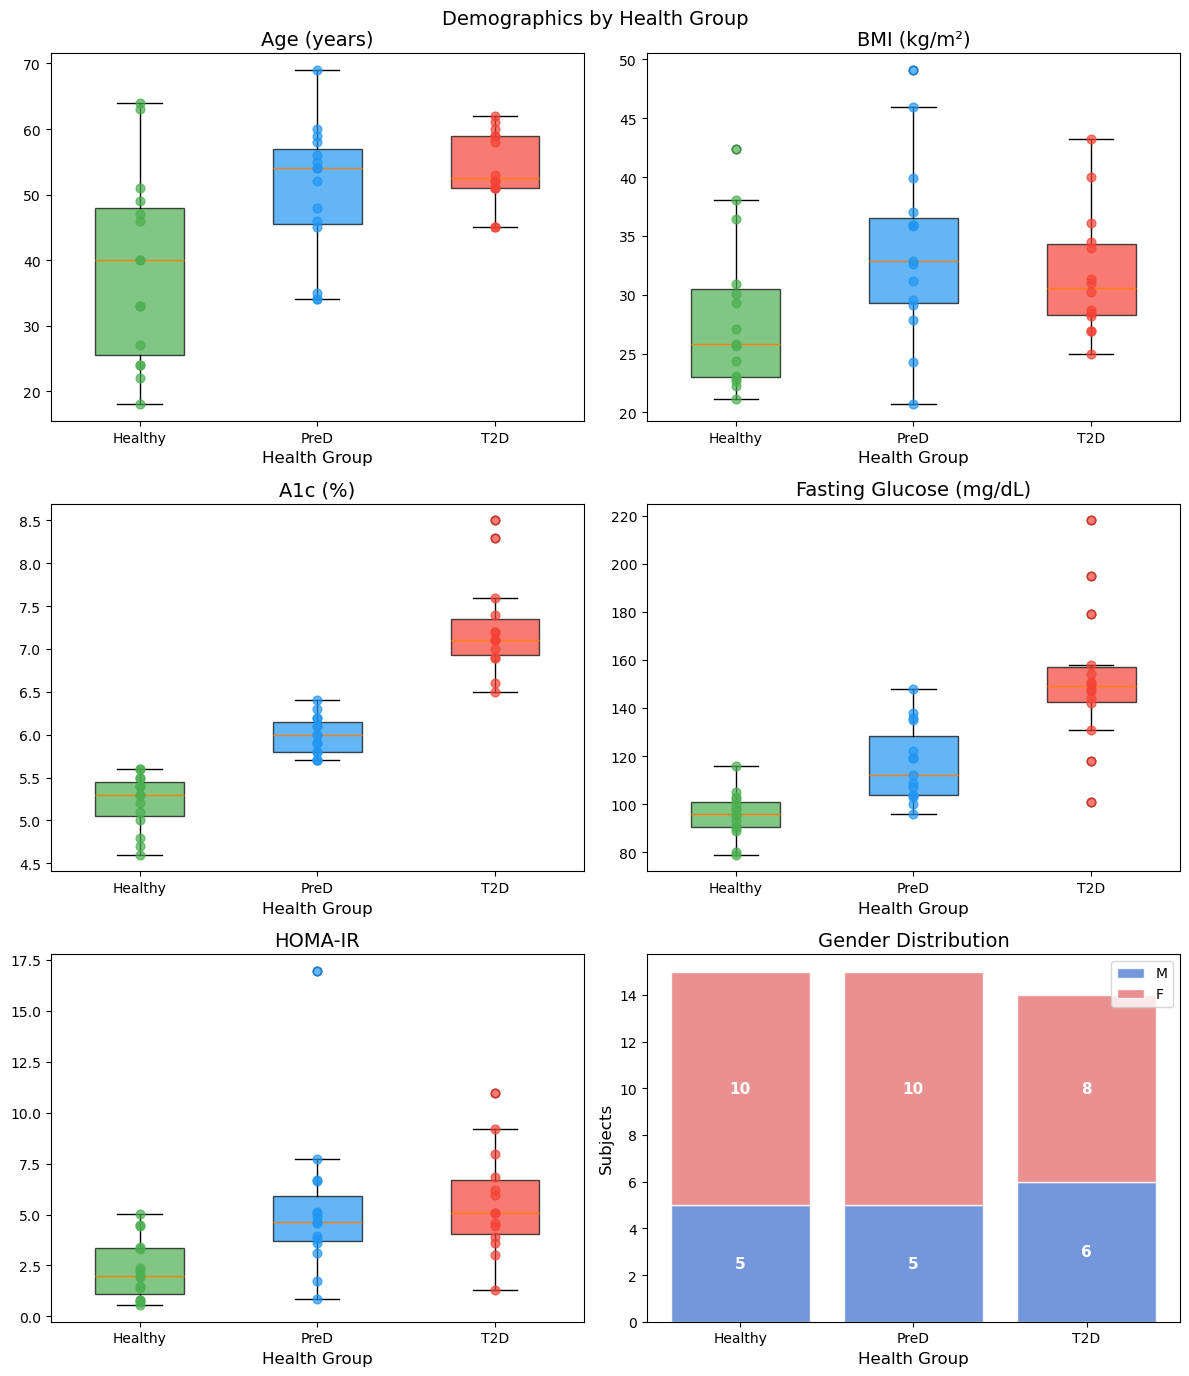

In [18]:
print("=" * 60)
print("1.3 — DEMOGRAPHICS OVERVIEW")
print("=" * 60)

bio_final = bio_clean[bio_clean['subject'].isin(meals_libre_df['subject'].unique())]

# Numerical summary per health group — use bio_clean (one row per subject)
demo_cols = ['Age', 'BMI', 'A1c', 'Fasting_glucose', 'HOMA_IR']
bio_stats = (bio_final
             .groupby('Health_group')[demo_cols]
             .agg(['mean', 'std', 'min', 'max'])
             .round(2))
print(bio_stats.to_string())

print("\nGender distribution:")
print(bio_final.groupby(['Health_group', 'Gender'])
               .size().unstack(fill_value=0).to_string())

# Plots
fig, axes = plt.subplots(3, 2, figsize=(12, 14))
axes = axes.flatten()

groups = ['Healthy', 'PreD', 'T2D']
colors = [HEALTH_COLORS[g] for g in groups]

demo_plot_cols = {
    'Age':             'Age (years)',
    'BMI':             'BMI (kg/m²)',
    'A1c':             'A1c (%)',
    'Fasting_glucose': 'Fasting Glucose (mg/dL)',
    'HOMA_IR':         'HOMA-IR',
}

for ax, (col, label) in zip(axes, demo_plot_cols.items()):
    data_by_group = [bio_final[bio_final['Health_group'] == g][col] for g in groups]

    bp = ax.boxplot(data_by_group, patch_artist=True,
                    labels=groups, widths=0.5)
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    # Overlay individual subject points
    for i, (g, d) in enumerate(zip(groups, data_by_group), 1):
        ax.scatter([i] * len(d), d,
                   color=HEALTH_COLORS[g], alpha=0.7, zorder=3, s=40)

    ax.set_title(label)
    ax.set_xlabel("Health Group")

# Last panel — Gender stacked bar
ax = axes[5]
gender_counts = (bio_final.groupby(['Health_group', 'Gender'])
                          .size().unstack(fill_value=0))
gender_counts = gender_counts.reindex(groups)
bottom = np.zeros(3)
for gender, color in zip(['M', 'F'], ['#5C85D6', '#E87D7D']):
    if gender in gender_counts.columns:
        vals = gender_counts[gender].values
        ax.bar(groups, vals, bottom=bottom,
               color=color, alpha=0.85, label=gender, edgecolor='white')
        for j, (v, b) in enumerate(zip(vals, bottom)):
            if v > 0:
                ax.text(j, b + v/2, str(v),
                        ha='center', va='center',
                        fontsize=11, fontweight='bold', color='white')
        bottom += vals

ax.set_title("Gender Distribution")
ax.set_xlabel("Health Group")
ax.set_ylabel("Subjects")
ax.legend()

plt.suptitle("Demographics by Health Group", fontsize=14)
plt.tight_layout()
plt.show()

In [19]:
print(meals_libre_df['iAUC_libre'].describe().round(1))
print(f"\nSkewness: {meals_libre_df['iAUC_libre'].skew():.2f}")

count    1170.00
mean     3132.20
std      2883.60
min         1.00
25%       984.90
50%      2282.90
75%      4238.10
max     15460.50
Name: iAUC_libre, dtype: float64

Skewness: 1.52


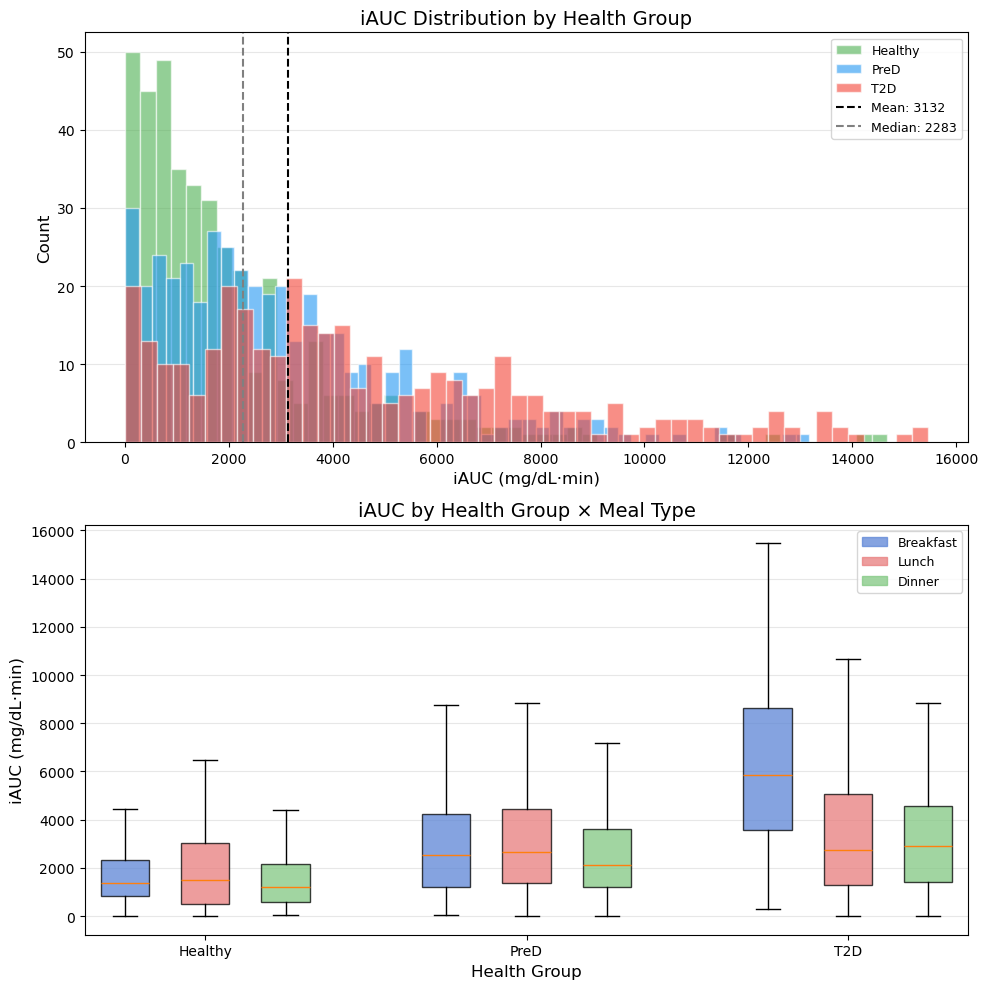

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

groups      = ['Healthy', 'PreD', 'T2D']
meal_types  = ['Breakfast', 'Lunch', 'Dinner']
meal_colors = ['#5C85D6', '#E87D7D', '#82C882']

# Panel 1: iAUC distribution by health group 
ax = axes[0]

for g in groups:
    subset = meals_libre_df[meals_libre_df['Health_group'] == g]['iAUC_libre']
    ax.hist(subset, bins=50, color=HEALTH_COLORS[g],
            edgecolor='white', alpha=0.6, label=g)

ax.axvline(meals_libre_df['iAUC_libre'].mean(), color='black',
           linestyle='--', linewidth=1.5,
           label=f"Mean: {meals_libre_df['iAUC_libre'].mean():.0f}")
ax.axvline(meals_libre_df['iAUC_libre'].median(), color='gray',
           linestyle='--', linewidth=1.5,
           label=f"Median: {meals_libre_df['iAUC_libre'].median():.0f}")

ax.set_title('iAUC Distribution by Health Group')
ax.set_xlabel('iAUC (mg/dL·min)')
ax.set_ylabel('Count')
ax.legend(fontsize=9)

# Panel 2: iAUC by health group × meal type (boxplot) 
ax = axes[1]
positions = []
data      = []
tick_pos  = []
tick_lab  = []
offset    = 0

for g in groups:
    group_positions = []
    for j, meal in enumerate(meal_types):
        subset = meals_libre_df[
            (meals_libre_df['Health_group'] == g) &
            (meals_libre_df['Meal_Type']    == meal)
        ]['iAUC_libre']
        pos = offset + j
        group_positions.append(pos)
        positions.append(pos)
        data.append(subset)

    tick_pos.append(np.mean(group_positions))
    tick_lab.append(g)
    offset += len(meal_types) + 1

bp = ax.boxplot(data, positions=positions, patch_artist=True,
                widths=0.6, showfliers=False)

for i, patch in enumerate(bp['boxes']):
    patch.set_facecolor(meal_colors[i % len(meal_types)])
    patch.set_alpha(0.75)

ax.set_xticks(tick_pos)
ax.set_xticklabels(tick_lab)
ax.set_title('iAUC by Health Group × Meal Type')
ax.set_xlabel('Health Group')
ax.set_ylabel('iAUC (mg/dL·min)')

handles = [plt.Rectangle((0,0),1,1, color=c, alpha=0.75) for c in meal_colors]
ax.legend(handles, meal_types, fontsize=9)

# Formatting
for ax in axes:
    ax.yaxis.grid(True, alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('iauc_eda.png', dpi=150, bbox_inches='tight')
plt.show()